In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f
from statsmodels.stats.multitest import multipletests
from copy import deepcopy
from tqdm import tqdm
import seaborn as sns
import scipy.stats as stats

In [ ]:
def f_test(n, k, r_sq):
    df_1 = k - 1
    df_2 = n - 2
    f_func = r_sq/((1-r_sq)/df_2)
    p_value = 1-f.cdf(f_func, df_1, df_2)
    return p_value


def linear_regression(x, y):
    n = len(x)
    mean_x = x.mean()
    mean_y = y.mean()
    var_x = x.var()
    cov_x_y = (sum(x*y) - (n*mean_x*mean_y))/(n-1)
    b_1 = cov_x_y/var_x
    b_0 = mean_y-(b_1*mean_x)
    y_h = b_0+b_1*x
    sse = sum(np.square(y-y_h))
    ssr = sum((np.square(y_h-mean_y)))
    sst = sse+ssr
    r_sq = ssr/sst
    p_value = f_test(n, 2, r_sq)
    return p_value

def cis_trans(eQTL_list, gen_pos, snp_loc, cis_acting_dist, p_adj):
    eQTL = deepcopy(eQTL_list)
    for i in range(0, len(eQTL)):
        gene = eQTL[i][0]
        snp = eQTL[i][1]
        #if snp in snp_loc.index:
        snp_chr = snp_loc.loc[snp]['Chr_Build37']
        gene_chr = gen_pos.loc[gene]['representative genome chromosome']
        if snp_chr == gene_chr:
            gene_start = gen_pos.loc[gene]['representative genome start']
            gene_end = gen_pos.loc[gene]['representative genome end']
            snp_pos = snp_loc.loc[snp]['Build37_position']
            if (abs(gene_start - snp_pos) <= cis_acting_dist) | (abs(snp_pos - gene_end) <= cis_acting_dist):
                eQTL[i].append('cis')
            else:
                eQTL[i].append('trans')
        else:
            eQTL[i].append('trans')
    for k in eQTL:
        k.append(p_adj.loc[k[0], k[1]])
    out = pd.DataFrame(data=eQTL, columns=['gene', 'snp', 'cis/trans', 'p-value'])
    return out

In [3]:
# data from preprocess
liver_pos_preprocessed = pd.read_excel('preprocess_sub\liver_pos_preprocessed.xlsx', index_col=0)
myeloid_pos_preprocessed = pd.read_excel('preprocess_sub\myeloid_pos_preprocessed.xlsx', index_col=0)
liver_exp_preprocessed = pd.read_excel('preprocess_sub\liver_exp_preprocessed.xlsx', index_col=0)
myeloid_exp_preprocessed = pd.read_excel('preprocess_sub\myeloid_exp_preprocessed.xlsx', index_col=0)
gene_pos_preprocessed = pd.read_excel('preprocess_sub\gene_pos_preprocessed.xlsx', index_col=0)



In [4]:
liver_bxd = liver_pos_preprocessed.filter(like='BXD')

myeloid_bxd = myeloid_pos_preprocessed.filter(like='BXD')

print(liver_bxd)

                BXD1 BXD2 BXD5 BXD6 BXD8 BXD9 BXD11 BXD12 BXD13 BXD14  ...  \
Locus                                                                  ...   
rs6269442          B    B    D    D    D    B     B     D     B     B  ...   
rs6376963          B    B    D    D    D    B     B     D     B     B  ...   
rs8236463          B    B    D    D    D    B     D     D     B     B  ...   
rs6360236          B    B    D    D    D    B     D     D     B     B  ...   
rs3655978          B    B    B    D    D    B     D     D     B     B  ...   
...              ...  ...  ...  ...  ...  ...   ...   ...   ...   ...  ...   
CEL-X_154048891    B    B    B    B    B    B     B     B     D     B  ...   
CEL-X_154259201    B    B    B    D    B    B     B     B     D     B  ...   
rs3657281          B    B    B    D    B    B     B     B     D     B  ...   
gnfX.146.867       B    B    B    D    B    B     B     B     D     B  ...   
DXMit223           B    B    B    D    B    B     B     B     D 

In [5]:
liver_bxd_pro = liver_bxd.applymap(lambda t: t.upper() if isinstance(t, str) else t)
liver_bxd_pro = liver_bxd_pro.replace({'B': 0, 'D': 2, 'H': 1})  # markings

myeloid_bxd_pro = myeloid_bxd.applymap(lambda t: t.upper() if isinstance(t, str) else t)
myeloid_bxd_pro = myeloid_bxd_pro.replace({'B': 0, 'D': 2, 'H': 1})  # markings

In [6]:
liver_bxd_pro, liver_exp = liver_bxd_pro.align(liver_exp_preprocessed, join='inner', axis=1)
myeloid_bxd_pro, myeloid_exp = myeloid_bxd_pro.align(myeloid_exp_preprocessed, join='inner', axis=1)

In [7]:
# change according to the data needed
genotypes = myeloid_bxd_pro
expression = myeloid_exp
print(genotypes)
#p_vals_df = pd.read_excel('xl\p_vals_liver_check.xlsx', index_col=0) # to prevent from long run

                 BXD1  BXD2  BXD6  BXD8  BXD9  BXD11  BXD12  BXD13  BXD14  \
Locus                                                                       
rs6269442           0     0     2     2     0      0      2      0      0   
rs8236463           0     0     2     2     0      2      2      0      0   
rs6360236           0     0     2     2     0      2      2      0      0   
rs3655978           0     0     2     2     0      2      2      0      0   
rs3669485           0     0     2     2     0      2      2      0      0   
...               ...   ...   ...   ...   ...    ...    ...    ...    ...   
CEL-X_143438541     0     0     0     0     2      0      0      2      0   
gnfX.141.820        0     0     0     0     0      0      0      2      0   
CEL-X_154259201     0     0     2     0     0      0      0      2      0   
rs3657281           0     0     2     0     0      0      0      2      0   
DXMit223            0     0     2     0     0      0      0      2      0   

In [8]:
p_val_list = []
for i, exp in tqdm(expression.iterrows()):
    p_val = genotypes.apply(lambda snp: linear_regression(x=snp.to_numpy(), y=exp.to_numpy()), axis=1)
    p_val_list.append(p_val)

9155it [42:43,  3.57it/s] 


In [9]:
p_vals_df = pd.DataFrame(p_val_list, index=expression.index, columns=genotypes.index.tolist()) #only when running p_vals
#p_vals_df.to_excel('xl\p_vals_liver.xlsx') #only when running p_vals

In [10]:
# multiple test correction
p_vals_vec = p_vals_df.values.flatten()
p_adj = multipletests(p_vals_vec, method="fdr_bh")[1]
p_adj = pd.DataFrame(p_adj.reshape(p_vals_df.shape), columns=p_vals_df.columns, index=p_vals_df.index)
p_adj_T = p_adj.T
# organise in a table, genotypes as rows, expression  - p values as columns
print(p_adj_T)


                 0610007C21Rik  0610007L01Rik  0610007P08Rik  0610007P14Rik  \
rs6269442             0.925958       0.896757       0.917376       0.995233   
rs8236463             0.804886       0.988862       0.831886       0.927310   
rs6360236             0.716508       0.941094       0.926279       0.922188   
rs3655978             0.723561       0.950674       0.911872       0.829400   
rs3669485             0.716707       0.970637       0.943929       0.901237   
...                        ...            ...            ...            ...   
CEL-X_143438541       0.857812       0.998614       0.931790       0.791288   
gnfX.141.820          0.826639       0.899238       0.954336       0.853604   
CEL-X_154259201       0.885162       0.844911       0.975814       0.821415   
rs3657281             0.909536       0.817267       0.981545       0.830980   
DXMit223              0.909536       0.817267       0.981545       0.830980   

                 0610007P22Rik  0610009B14Rik  0610

In [11]:
eQTL_list = []
eQTL_dict = {}
for snp, p_val in p_adj_T.iterrows():
    low_p = p_val[p_val <= 0.05]
    if low_p.empty:
        eQTL_dict[snp] = [] 
    else:
        eQTL_dict[low_p.name] = low_p.index.tolist()
        eQTL_list.extend([[gene, low_p.name] for gene in low_p.index.tolist()])
len(eQTL_list)

1643

In [12]:
eQTL_assoc = {x:len(y) for x,y in eQTL_dict.items()}
genotype_info = myeloid_pos_preprocessed[['Chr_Build37', 'Build37_position']]
gen_eQTL_comb = (
    genotype_info
    .join(pd.DataFrame.from_dict(eQTL_assoc, orient='index'), how='left')
    .rename(columns={0: 'num_associated_genes'})
)

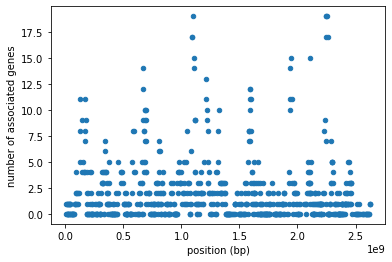

In [13]:
gen_eQTL_comb.plot.scatter(x='Build37_position', y='num_associated_genes')
plt.xlabel("position (bp)")
plt.ylabel("number of associated genes")
plt.savefig('myeloid_associated_genes')

In [14]:
print(genotype_info)

                 Chr_Build37  Build37_position
Locus                                         
rs6269442                  1           3482276
rs8236463                  1           5579194
rs6360236                  1          11073905
rs3655978                  1          13373071
rs3669485                  1          13975253
...                      ...               ...
CEL-X_143438541           20        2612467917
gnfX.141.820              20        2620505839
CEL-X_154259201           20        2623209565
rs3657281                 20        2623433385
DXMit223                  20        2626223800

[850 rows x 2 columns]


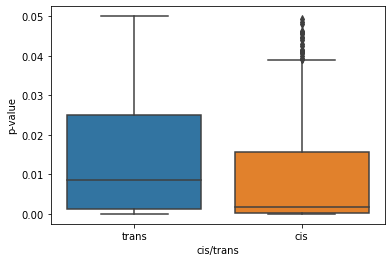

In [22]:
eQTL_cis_trans = cis_trans(eQTL_list, gene_pos_preprocessed, genotype_info, 2000000, p_adj)
sns.boxplot(x="cis/trans", y="p-value", data=eQTL_cis_trans)
plt.savefig('xl\cis_trans_plot_myeloid')

In [16]:
cis_count = eQTL_cis_trans['cis/trans'].str.count('cis').sum()

print("Total occurrences of 'cis':", cis_count)

Total occurrences of 'cis': 459


In [17]:
gene_list = eQTL_cis_trans['gene']
gene_pos = gene_pos_preprocessed.loc[gene_list, 'representative genome start']
snp_list = eQTL_cis_trans['snp']
snp_pos = genotype_info.loc[snp_list, 'Build37_position']
eQTL_pos = eQTL_cis_trans[['gene', 'snp']].replace({'gene': gene_pos, 'snp': snp_pos})

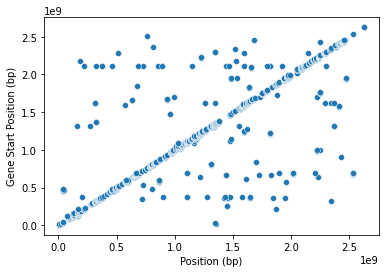

In [18]:
sns.scatterplot(data=eQTL_pos, x='gene', y='snp')
plt.xlabel('Position (bp)')
plt.ylabel('Gene Start Position (bp)')
plt.savefig('fig_scatterplot_myeloid')

# eQTL_cis_trans.to_excel('eQTL_Output\eQTLs_liver.xlsx')